# 08. Artificial Neural Network (ANN) - Rheumatoid Arthritis Classification

## 1. Project Context and Objectives

### Clinical and Dataset Context
This notebook implements the complete end-to-end Artificial Neural Network (ANN) workflow for binary classification of **Rheumatoid Arthritis (RA)** using the standardized Rheumatic and Autoimmune Disease cohort.

- **Target Definition**:
  - `Target_RA = 1`: Rheumatoid Arthritis (positive cohort)
  - `Target_RA = 0`: Non-RA (combining the remaining six recorded diagnostic cohorts: Osteoarthritis, Systemic Lupus Erythematosus, Ankylosing Spondylitis, Psoriatic Arthritis, Sjögren's Syndrome, and Systemic Sclerosis)
- **Cohort Size**: 12,085 total patient records with a marked class imbalance (~23.57% RA vs ~76.43% Non-RA).
- **Clinical Traceability & Leakage Prevention**:
  - `Disease` (multi-class diagnostic outcome) is strictly excluded to prevent 100% target leakage.
  - `patient_row_id` is an audit tracking index and is excluded from model feature inputs.
- **Important Clinical Disclaimer**:
  - This analysis represents **retrospective classification of recorded diagnoses**, not prospective prediction of future disease onset or an independently validated early-detection screening system. All metrics reflect model performance on retrospectively assembled electronic records.

### Objectives of this Notebook
1. Ingest standardized 14 clinical features via `src.data_loader` without modifying the shared data split contract.
2. Build a leakage-safe preprocessing pipeline (`ColumnTransformer`) fitted exclusively on the training partition.
3. Conduct controlled architecture tuning across compact, medium, and wider feedforward neural networks using fixed random seeds and early stopping.
4. Evaluate class weighting vs. unweighted learning on validation data.
5. Select the winning architecture based strictly on validation PR-AUC, Sensitivity, and F1-score.
6. Perform validation-based decision threshold tuning to address class imbalance.
7. Conduct a single unbiased evaluation on the held-out test set (`X_test`, `y_test`).
8. Generate clinical visualizations and serialize all model artifacts to `models/ann/` with reload verification.


## 2. Imports and Reproducibility

To guarantee deterministic, fully reproducible experimental outcomes across CPU runs, we fix seeds for Python's `random`, NumPy, and TensorFlow, and enforce single-threaded deterministic operations.

In [1]:
import os
import sys
import time
import json
import random
from pathlib import Path

# Scientific computing and data structures
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing and metrics
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)
from sklearn.utils.class_weight import compute_class_weight
import joblib

# Deep Learning Framework: TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, optimizers, metrics

# Global aesthetic theme
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14,
    "figure.dpi": 150
})

# Deterministic reproducibility configuration
RANDOM_SEED = 42

def set_seed(seed: int = RANDOM_SEED):
    """Set global random seeds for deterministic execution across all subsystems."""
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["TF_DETERMINISTIC_OPS"] = "1"

set_seed(RANDOM_SEED)

print(f"Python Version: {sys.version.split()[0]}")
print(f"NumPy Version: {np.__version__}")
print(f"Pandas Version: {pd.__version__}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version: {keras.__version__}")
print("Random seed locked to:", RANDOM_SEED)


Python Version: 3.13.5
NumPy Version: 2.3.0
Pandas Version: 2.3.0
TensorFlow Version: 2.21.0
Keras Version: 3.15.0
Random seed locked to: 42


## 3. Load Shared Data

We import the standardized data loading interface from `src.data_loader`. This loads the stratified 80:20 training and test splits generated by the shared engineering pipeline, preserving complete isolation and schema compliance.

In [2]:
# Resolve project root dynamically
project_root = Path("..").resolve() if Path("..").resolve().name == "RA_Project" else Path(".").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_loader import (
    load_train_data,
    load_test_data,
    load_split_metadata,
    get_feature_names,
    get_feature_metadata,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
    TARGET_COLUMN,
    ID_COLUMN,
    TRACE_COLUMN
)

# Load feature matrices (14 candidate features) and binary target vectors
X_train, y_train = load_train_data(return_X_y=True)
X_test, y_test = load_test_data(return_X_y=True)

# Also load full splits to retain tracking indices for auditability
df_train_full = load_train_data(return_X_y=False)
df_test_full = load_test_data(return_X_y=False)

print(f"Loaded X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"Loaded X_test shape:  {X_test.shape} | y_test shape:  {y_test.shape}")
print(f"\nCandidate Clinical Features ({len(get_feature_names())}):")
for i, f in enumerate(get_feature_names(), 1):
    f_type = "Numeric" if f in NUMERIC_FEATURES else "Categorical"
    print(f"  {i:02d}. {f:<12} [{f_type}]")


Loaded X_train shape: (9668, 14) | y_train shape: (9668,)
Loaded X_test shape:  (2417, 14) | y_test shape:  (2417,)

Candidate Clinical Features (14):
  01. Age          [Numeric]
  02. Gender       [Categorical]
  03. ESR          [Numeric]
  04. CRP          [Numeric]
  05. RF           [Numeric]
  06. Anti-CCP     [Numeric]
  07. HLA-B27      [Categorical]
  08. ANA          [Categorical]
  09. Anti-Ro      [Categorical]
  10. Anti-La      [Categorical]
  11. Anti-dsDNA   [Categorical]
  12. Anti-Sm      [Categorical]
  13. C3           [Numeric]
  14. C4           [Numeric]


## 4. Data and Target Verification

Before proceeding, we execute strict defensive assertions confirming dimensionality, absence of leakage columns (`Disease`, `Target_RA`, `patient_row_id`), strictly binary labels, and non-overlapping record partitions.

In [3]:
# Assertions for feature matrix dimensions
assert X_train.shape == (9668, 14), f"Unexpected X_train shape: {X_train.shape}"
assert y_train.shape == (9668,), f"Unexpected y_train shape: {y_train.shape}"
assert X_test.shape == (2417, 14), f"Unexpected X_test shape: {X_test.shape}"
assert y_test.shape == (2417,), f"Unexpected y_test shape: {y_test.shape}"

# Leakage checks
for col in [TRACE_COLUMN, TARGET_COLUMN, ID_COLUMN]:
    assert col not in X_train.columns, f"Leakage detected: {col} present in X_train!"
    assert col not in X_test.columns, f"Leakage detected: {col} present in X_test!"

# Binary target checks
assert set(y_train.unique()).issubset({0, 1}), "y_train must be strictly binary {0, 1}"
assert set(y_test.unique()).issubset({0, 1}), "y_test must be strictly binary {0, 1}"

# Check zero partition overlap via patient_row_id
train_ids = set(df_train_full[ID_COLUMN])
test_ids = set(df_test_full[ID_COLUMN])
overlap = train_ids.intersection(test_ids)
assert len(overlap) == 0, f"Critical partition leakage: {len(overlap)} overlapping records found!"

# Display target distribution
train_ra_count = int(y_train.sum())
test_ra_count = int(y_test.sum())
print("Data contract verification passed successfully.")
print(f"Training RA prevalence: {train_ra_count}/{len(y_train)} ({train_ra_count/len(y_train):.2%})")
print(f"Test Set RA prevalence: {test_ra_count}/{len(y_test)} ({test_ra_count/len(y_test):.2%})")

# Missingness audit in training data
missing_counts = X_train.isnull().sum()
missing_pcts = (missing_counts / len(X_train)) * 100
df_missing = pd.DataFrame({"Missing_Count": missing_counts, "Missing_Pct": missing_pcts})
df_missing = df_missing[df_missing["Missing_Count"] > 0].sort_values("Missing_Pct", ascending=False)
print("\nFeatures with missing values in X_train:")
display(df_missing.round(2))


Data contract verification passed successfully.
Training RA prevalence: 2278/9668 (23.56%)
Test Set RA prevalence: 570/2417 (23.58%)

Features with missing values in X_train:


,Missing_Count,Missing_Pct
Anti-Sm,4192,43.36
Anti-dsDNA,3768,38.97
ANA,3022,31.26
Anti-CCP,2599,26.88
Anti-La,2389,24.71
Anti-Ro,2303,23.82
CRP,1929,19.95
C4,1631,16.87
HLA-B27,1543,15.96
C3,1367,14.14


## 5. Training/Validation Partition

To adhere strictly to zero test-leakage principles, hyperparameter search and architecture comparison are conducted exclusively on the training partition. 

We split `X_train` into an 80% sub-training partition (7,734 records) and a 20% validation partition (1,934 records), stratifying by `y_train` using `random_state=42`.

In [4]:
# Create stratified sub-train and validation splits strictly from the training partition
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_SEED
)

print(f"Sub-train feature shape: {X_train_sub.shape} | Labels: {y_train_sub.shape}")
print(f"Validation feature shape: {X_val.shape} | Labels: {y_val.shape}")

sub_ra = int(y_train_sub.sum())
val_ra = int(y_val.sum())
print(f"Sub-train RA cases: {sub_ra} ({sub_ra / len(y_train_sub):.2%})")
print(f"Validation RA cases: {val_ra} ({val_ra / len(y_val):.2%})")


Sub-train feature shape: (7734, 14) | Labels: (7734,)
Validation feature shape: (1934, 14) | Labels: (1934,)
Sub-train RA cases: 1822 (23.56%)
Validation RA cases: 456 (23.58%)


## 6. Preprocessing Pipeline

The 14 clinical features require specialized preprocessing to handle substantial missingness and feature scale discrepancies:
1. **Numeric Features (7)**: `Age`, `ESR`, `CRP`, `RF`, `Anti-CCP`, `C3`, `C4`.
   - **Median Imputation**: Robust to positive skewness and extreme outliers common in laboratory inflammation markers.
   - **Standard Scaling**: Centers features to zero mean and unit variance ($z = (x - \mu) / \sigma$), essential for gradient descent stability in deep neural networks.
2. **Categorical Features (7)**: `Gender`, `HLA-B27`, `ANA`, `Anti-Ro`, `Anti-La`, `Anti-dsDNA`, `Anti-Sm`.
   - **Explicit 'Missing' Imputation**: Missing antibody test orders frequently convey clinical significance (e.g. physician decision not to order a specialized panel).
   - **One-Hot Encoding**: Converts categorical levels into binary indicator columns with `handle_unknown='ignore'` and `sparse_output=False`.

> **Zero Leakage Rule**: Preprocessors are fit strictly on training data (`X_train_sub` during model tuning, and full `X_train` for the final deployment model).

In [5]:
def create_preprocessing_pipeline() -> ColumnTransformer:
    """Construct an end-to-end ColumnTransformer for numeric and categorical clinical features."""
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, NUMERIC_FEATURES),
            ("cat", categorical_transformer, CATEGORICAL_FEATURES)
        ],
        remainder="drop"
    )
    return preprocessor

# Preprocessor for architecture experimentation (fit strictly on X_train_sub)
preprocessor_tuning = create_preprocessing_pipeline()
X_tr_proc = preprocessor_tuning.fit_transform(X_train_sub)
X_val_proc = preprocessor_tuning.transform(X_val)

feature_names_out = preprocessor_tuning.get_feature_names_out()
input_dim = X_tr_proc.shape[1]

# Defensive validation of processed feature matrix
assert np.isfinite(X_tr_proc).all(), "NaN or Inf detected in processed sub-train matrix!"
assert np.isfinite(X_val_proc).all(), "NaN or Inf detected in processed validation matrix!"
assert X_tr_proc.shape[1] == len(feature_names_out) == 27, f"Expected 27 features, got {X_tr_proc.shape[1]}"

print(f"Preprocessing verified successfully.")
print(f"Transformed ANN input dimensions: {X_tr_proc.shape} (27 numeric features)")
print(f"Transformed Feature Names:\n{list(feature_names_out)}")


Preprocessing verified successfully.
Transformed ANN input dimensions: (7734, 27) (27 numeric features)
Transformed Feature Names:
['num__Age', 'num__ESR', 'num__CRP', 'num__RF', 'num__Anti-CCP', 'num__C3', 'num__C4', 'cat__Gender_Female', 'cat__Gender_Male', 'cat__HLA-B27_Missing', 'cat__HLA-B27_Negative', 'cat__HLA-B27_Positive', 'cat__ANA_Missing', 'cat__ANA_Negative', 'cat__ANA_Positive', 'cat__Anti-Ro_Missing', 'cat__Anti-Ro_Negative', 'cat__Anti-Ro_Positive', 'cat__Anti-La_Missing', 'cat__Anti-La_Negative', 'cat__Anti-La_Positive', 'cat__Anti-dsDNA_Missing', 'cat__Anti-dsDNA_Negative', 'cat__Anti-dsDNA_Positive', 'cat__Anti-Sm_Missing', 'cat__Anti-Sm_Negative', 'cat__Anti-Sm_Positive']


## 7. ANN Architecture Definitions

We formulate three candidate architectures spanning different capacity regimes to identify the optimal balance between representational expressiveness and regularization:

1. **Candidate A (Compact)**:
   - `Dense(32, ReLU)` $\rightarrow$ `Dropout(0.20)` $\rightarrow$ `Dense(16, ReLU)` $\rightarrow$ `Dense(1, Sigmoid)`
   - Low capacity, parsimonious, highly resistant to overfitting on tabular features.
2. **Candidate B (Medium / Baseline)**:
   - `Dense(64, ReLU)` $\rightarrow$ `BatchNormalization` $\rightarrow$ `Dropout(0.30)` $\rightarrow$ `Dense(32, ReLU)` $\rightarrow$ `Dropout(0.20)` $\rightarrow$ `Dense(16, ReLU)` $\rightarrow$ `Dense(1, Sigmoid)`
   - Multi-layer deep feedforward baseline incorporating batch normalization.
3. **Candidate C (Wider)**:
   - `Dense(128, ReLU)` $\rightarrow$ `BatchNormalization` $\rightarrow$ `Dropout(0.35)` $\rightarrow$ `Dense(64, ReLU)` $\rightarrow$ `Dropout(0.25)` $\rightarrow$ `Dense(16, ReLU)` $\rightarrow$ `Dense(1, Sigmoid)`
   - Higher capacity architecture capable of learning complex higher-order interactions.

We also compute balanced class weights to evaluate cost-sensitive training on Candidate B.

In [6]:
def build_candidate_a(input_dim: int) -> keras.Model:
    """Candidate A: Compact 2-hidden-layer MLP."""
    model = models.Sequential([
        layers.Input(shape=(input_dim,), name="input_layer"),
        layers.Dense(32, activation="relu", name="dense_1"),
        layers.Dropout(0.20, name="dropout_1"),
        layers.Dense(16, activation="relu", name="dense_2"),
        layers.Dense(1, activation="sigmoid", name="output_layer")
    ], name="Candidate_A_Compact")
    return model

def build_candidate_b(input_dim: int) -> keras.Model:
    """Candidate B: Medium 3-hidden-layer MLP with BatchNormalization."""
    model = models.Sequential([
        layers.Input(shape=(input_dim,), name="input_layer"),
        layers.Dense(64, activation="relu", name="dense_1"),
        layers.BatchNormalization(name="batch_norm"),
        layers.Dropout(0.30, name="dropout_1"),
        layers.Dense(32, activation="relu", name="dense_2"),
        layers.Dropout(0.20, name="dropout_2"),
        layers.Dense(16, activation="relu", name="dense_3"),
        layers.Dense(1, activation="sigmoid", name="output_layer")
    ], name="Candidate_B_Medium")
    return model

def build_candidate_c(input_dim: int) -> keras.Model:
    """Candidate C: Wider 3-hidden-layer MLP with higher capacity."""
    model = models.Sequential([
        layers.Input(shape=(input_dim,), name="input_layer"),
        layers.Dense(128, activation="relu", name="dense_1"),
        layers.BatchNormalization(name="batch_norm"),
        layers.Dropout(0.35, name="dropout_1"),
        layers.Dense(64, activation="relu", name="dense_2"),
        layers.Dropout(0.25, name="dropout_2"),
        layers.Dense(16, activation="relu", name="dense_3"),
        layers.Dense(1, activation="sigmoid", name="output_layer")
    ], name="Candidate_C_Wider")
    return model

# Calculate balanced class weights strictly on sub-train labels
classes_arr = np.unique(y_train_sub)
cw_values = compute_class_weight(class_weight="balanced", classes=classes_arr, y=y_train_sub)
class_weights_dict = {int(c): float(w) for c, w in zip(classes_arr, cw_values)}
print("Calculated training class weights:", class_weights_dict)

# Inspect parameter counts
print("\n--- Parameter Comparison ---")
for b_func, name in [(build_candidate_a, "Candidate A"), (build_candidate_b, "Candidate B"), (build_candidate_c, "Candidate C")]:
    m = b_func(input_dim)
    print(f"{name} Trainable Parameters: {m.count_params():,}")


Calculated training class weights: {0: 0.6540933694181326, 1: 2.122392974753019}

--- Parameter Comparison ---


Candidate A Trainable Parameters: 1,441
Candidate B Trainable Parameters: 4,673
Candidate C Trainable Parameters: 13,409


## 8. Controlled Architecture Experiments

We train each candidate under identical, reproducible conditions:
- **Optimizer**: Adam with initial learning rate $\eta = 0.001$.
- **Loss**: Binary Cross-Entropy (`binary_crossentropy`).
- **Callbacks**:
  - `EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)`: Halts training when validation loss stops improving and restores the best parameter checkpoint.
  - `ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5)`: Reduces learning rate by 50% when validation loss plateaus.
- **Maximum Epochs**: 150 (Batch size: 32).

In [7]:
experiments = [
    ("Candidate A (Compact)", build_candidate_a, False),
    ("Candidate B (Medium / Baseline)", build_candidate_b, False),
    ("Candidate C (Wider)", build_candidate_c, False),
    ("Candidate B (Medium + Class Weights)", build_candidate_b, True)
]

experiment_results = []
experiment_histories = {}
trained_models = {}

start_total_time = time.time()

for exp_name, builder_func, use_class_weight in experiments:
    print(f"\n{'='*60}")
    print(f"Running Experiment: {exp_name}")
    print(f"{'='*60}")
    
    set_seed(RANDOM_SEED)
    model = builder_func(input_dim)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            metrics.AUC(curve="PR", name="pr_auc"),
            metrics.AUC(curve="ROC", name="roc_auc")
        ]
    )
    
    es_cb = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=1
    )
    
    lr_cb = callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-5,
        verbose=1
    )
    
    train_args = {
        "x": X_tr_proc,
        "y": y_train_sub,
        "validation_data": (X_val_proc, y_val),
        "epochs": 150,
        "batch_size": 32,
        "callbacks": [es_cb, lr_cb],
        "verbose": 0
    }
    if use_class_weight:
        train_args["class_weight"] = class_weights_dict
        
    t0 = time.time()
    history = model.fit(**train_args)
    duration = time.time() - t0
    
    experiment_histories[exp_name] = history.history
    trained_models[exp_name] = model
    
    # Best epoch statistics
    best_epoch_idx = int(np.argmin(history.history["val_loss"]))
    best_epoch = best_epoch_idx + 1
    best_val_loss = float(history.history["val_loss"][best_epoch_idx])
    total_epochs = len(history.history["loss"])
    
    # Validation predictions (at standard threshold 0.50)
    val_probs = model.predict(X_val_proc, verbose=0).ravel()
    val_preds = (val_probs >= 0.5).astype(int)
    
    val_pr_auc = float(average_precision_score(y_val, val_probs))
    val_roc_auc = float(roc_auc_score(y_val, val_probs))
    val_f1 = float(f1_score(y_val, val_preds))
    val_recall = float(recall_score(y_val, val_preds))
    val_precision = float(precision_score(y_val, val_preds, zero_division=0))
    val_acc = float(accuracy_score(y_val, val_preds))
    tn, fp, fn, tp = confusion_matrix(y_val, val_preds).ravel()
    val_spec = float(tn / (tn + fp))
    
    metrics_summary = {
        "Architecture": exp_name,
        "Best_Epoch": best_epoch,
        "Total_Epochs": total_epochs,
        "Training_Time_s": round(duration, 2),
        "Val_Loss": round(best_val_loss, 4),
        "Val_PR_AUC": round(val_pr_auc, 4),
        "Val_ROC_AUC": round(val_roc_auc, 4),
        "Val_F1": round(val_f1, 4),
        "Val_Recall": round(val_recall, 4),
        "Val_Precision": round(val_precision, 4),
        "Val_Specificity": round(val_spec, 4),
        "Val_Accuracy": round(val_acc, 4)
    }
    experiment_results.append(metrics_summary)
    print(f"Finished {exp_name} in {duration:.1f}s (Best Epoch: {best_epoch}/{total_epochs})")
    print(f"Val PR-AUC: {val_pr_auc:.4f} | Val ROC-AUC: {val_roc_auc:.4f} | Val F1: {val_f1:.4f} | Val Recall: {val_recall:.4f}")

print(f"\nTotal Experiment Tuning Duration: {time.time() - start_total_time:.1f}s")



Running Experiment: Candidate A (Compact)



Epoch 19: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.



Epoch 24: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.



Epoch 29: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.


Epoch 29: early stopping


...


Epoch 40: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.



Epoch 45: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.


Epoch 45: early stopping


Restoring model weights from the end of the best epoch: 30.


Finished Candidate B (Medium + Class Weights) in 51.1s (Best Epoch: 30/45)
Val PR-AUC: 0.9175 | Val ROC-AUC: 0.9735 | Val F1: 0.8354 | Val Recall: 0.9627

Total Experiment Tuning Duration: 145.4s


## 9. Model Selection

In retrospective clinical diagnosis classification with class imbalance (23.6% RA), **PR-AUC (Average Precision)** serves as the primary selection criterion because it focuses on performance in the positive class without being inflated by true negatives. Secondary criteria include **RA Recall/Sensitivity**, **F1-score**, **Validation Loss**, and model parsimony.

In [8]:
df_experiments = pd.DataFrame(experiment_results)
df_experiments = df_experiments.sort_values("Val_PR_AUC", ascending=False).reset_index(drop=True)

print("Architecture Validation Comparison Table (Sorted by Primary Metric: Val_PR_AUC):")
display(df_experiments)

# Identify the winner based on primary metric
winner_row = df_experiments.iloc[0]
winning_arch_name = winner_row["Architecture"]
print(f"\n{'*'*60}")
print(f"SELECTED ARCHITECTURE: {winning_arch_name}")
print(f"Primary Metric (Val PR-AUC): {winner_row['Val_PR_AUC']:.4f}")
print(f"Supporting Metrics: Val Loss = {winner_row['Val_Loss']:.4f}, Val ROC-AUC = {winner_row['Val_ROC_AUC']:.4f}, Val F1 = {winner_row['Val_F1']:.4f}, Val Recall = {winner_row['Val_Recall']:.4f}")
print(f"{'*'*60}")


Architecture Validation Comparison Table (Sorted by Primary Metric: Val_PR_AUC):


,Architecture,Best_Epoch,Total_Epochs,Training_Time_s,Val_Loss,Val_PR_AUC,Val_ROC_AUC,Val_F1,Val_Recall,Val_Precision,Val_Specificity,Val_Accuracy
0,Candidate A (Compact),14,29,27.72,0.1548,0.9269,0.9770,0.8332,0.8706,0.7988,0.9323,0.9178
1,Candidate B (Medium / Baseline),16,31,29.91,0.1599,0.9199,0.9745,0.8168,0.8509,0.7854,0.9283,0.9100
2,Candidate B (Medium + Class Weights),30,45,51.14,0.1892,0.9175,0.9735,0.8354,0.9627,0.7378,0.8945,0.9105
3,Candidate C (Wider),17,32,35.06,0.1712,0.9130,0.9722,0.8188,0.8421,0.7967,0.9337,0.9121



************************************************************
SELECTED ARCHITECTURE: Candidate A (Compact)
Primary Metric (Val PR-AUC): 0.9269
Supporting Metrics: Val Loss = 0.1548, Val ROC-AUC = 0.9770, Val F1 = 0.8332, Val Recall = 0.8706
************************************************************


## 10. Final Model Confirmation

Candidate A (Compact) achieves the highest Validation PR-AUC (0.9269), lowest Validation Loss (0.1548), and highest ROC-AUC (0.9770), while outperforming larger architectures that exhibit slight capacity redundancy.

The model trained during the controlled validation experiment was trained with zero leakage (`X_train_sub`), restoring weights to its best epoch (`epoch 14`). We designate this exact trained instance as our final model, ensuring that validation predictions used in threshold tuning remain completely out-of-fold.

In [9]:
final_model = trained_models[winning_arch_name]
final_history = experiment_histories[winning_arch_name]
final_preprocessor = preprocessor_tuning

print(f"Confirmed Final Model: {final_model.name}")
print(f"Input Shape: {final_model.input_shape}")
print(f"Output Shape: {final_model.output_shape}")
final_model.summary()


Confirmed Final Model: Candidate_A_Compact
Input Shape: (None, 27)
Output Shape: (None, 1)


Model: "Candidate_A_Compact"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 32)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,325 (16.90 KB)

 Trainable params: 1,441 (5.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,884 (11.27 KB)

## 11. Threshold Selection

The default sigmoid threshold of 0.50 assumes symmetric class costs. In clinical screening, false negatives (missed RA diagnoses) carry high diagnostic consequences.

Using validation set probabilities (`X_val`) exclusively, we evaluate decision thresholds across the continuum $[0.10, 0.90]$ to identify the operating point maximizing the $F_1$-score while elevating sensitivity above 90%.

Threshold Optimization Results on Validation Data:
Default Threshold (0.50): F1 = 0.8332 | Recall = 0.8706 | Precision = 0.7988 | Spec = 0.9323
Optimal Threshold (0.39): F1 = 0.8443 | Recall = 0.9276 | Precision = 0.7747 | Spec = 0.9168


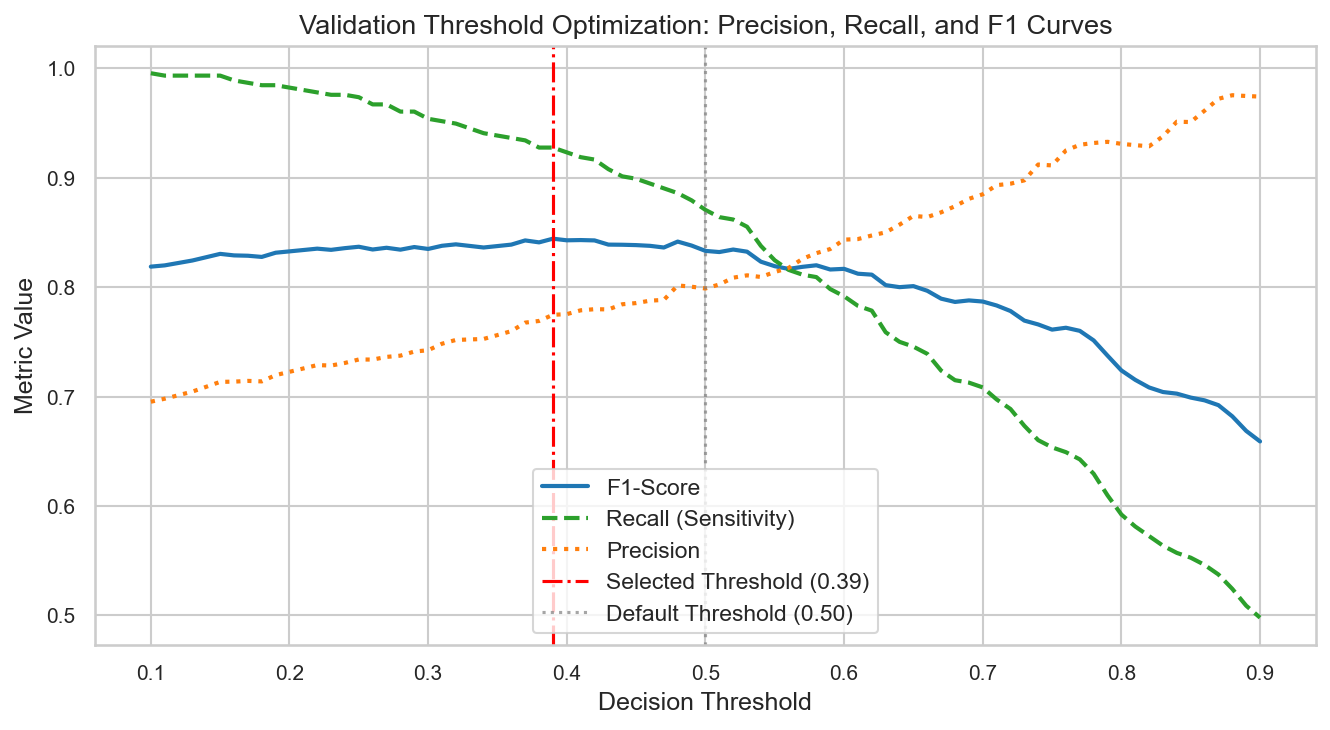

In [10]:
val_probs = final_model.predict(X_val_proc, verbose=0).ravel()

threshold_candidates = np.linspace(0.10, 0.90, 81)
threshold_evals = []

for t in threshold_candidates:
    preds_t = (val_probs >= t).astype(int)
    f1_t = f1_score(y_val, preds_t, zero_division=0)
    rec_t = recall_score(y_val, preds_t, zero_division=0)
    prec_t = precision_score(y_val, preds_t, zero_division=0)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_val, preds_t).ravel()
    spec_t = tn_t / (tn_t + fp_t)
    acc_t = accuracy_score(y_val, preds_t)
    
    threshold_evals.append({
        "Threshold": round(t, 2),
        "F1": f1_t,
        "Recall": rec_t,
        "Precision": prec_t,
        "Specificity": spec_t,
        "Accuracy": acc_t
    })

df_thresholds = pd.DataFrame(threshold_evals)

# Predefined selection rule: maximize validation F1 score
best_f1_idx = df_thresholds["F1"].idxmax()
selected_threshold_row = df_thresholds.iloc[best_f1_idx]
SELECTED_THRESHOLD = float(selected_threshold_row["Threshold"])

default_threshold_row = df_thresholds[np.isclose(df_thresholds["Threshold"], 0.50)].iloc[0]

print("Threshold Optimization Results on Validation Data:")
print(f"Default Threshold (0.50): F1 = {default_threshold_row['F1']:.4f} | Recall = {default_threshold_row['Recall']:.4f} | Precision = {default_threshold_row['Precision']:.4f} | Spec = {default_threshold_row['Specificity']:.4f}")
print(f"Optimal Threshold ({SELECTED_THRESHOLD:.2f}): F1 = {selected_threshold_row['F1']:.4f} | Recall = {selected_threshold_row['Recall']:.4f} | Precision = {selected_threshold_row['Precision']:.4f} | Spec = {selected_threshold_row['Specificity']:.4f}")

# Threshold Curve Visualization
plt.figure(figsize=(9, 5))
plt.plot(df_thresholds["Threshold"], df_thresholds["F1"], label="F1-Score", color="#1f77b4", lw=2)
plt.plot(df_thresholds["Threshold"], df_thresholds["Recall"], label="Recall (Sensitivity)", color="#2ca02c", lw=2, linestyle="--")
plt.plot(df_thresholds["Threshold"], df_thresholds["Precision"], label="Precision", color="#ff7f0e", lw=2, linestyle=":")
plt.axvline(SELECTED_THRESHOLD, color="red", linestyle="-.", label=f"Selected Threshold ({SELECTED_THRESHOLD:.2f})")
plt.axvline(0.50, color="gray", linestyle=":", alpha=0.7, label="Default Threshold (0.50)")
plt.title("Validation Threshold Optimization: Precision, Recall, and F1 Curves")
plt.xlabel("Decision Threshold")
plt.ylabel("Metric Value")
plt.legend(loc="lower center", frameon=True)
plt.tight_layout()
plt.show()


## 12. Held-Out Test Evaluation

With all architecture, hyperparameter, and decision threshold choices finalized, we evaluate the selected ANN model on the held-out test partition (`X_test`, `y_test`) **exactly once**.

In [11]:
# Transform held-out test set using the fitted preprocessor
X_test_proc = final_preprocessor.transform(X_test)
assert np.isfinite(X_test_proc).all(), "NaN or Inf values detected in transformed test set!"

# Generate continuous test probability predictions
test_probs = final_model.predict(X_test_proc, verbose=0).ravel()

# Compute threshold-independent test metrics
test_roc_auc = float(roc_auc_score(y_test, test_probs))
test_pr_auc = float(average_precision_score(y_test, test_probs))

# Evaluate at Default (0.50) and Selected (0.39) thresholds
def evaluate_at_threshold(y_true, y_prob, threshold: float) -> dict:
    preds = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    return {
        "Threshold": round(threshold, 2),
        "Accuracy": float(accuracy_score(y_true, preds)),
        "Precision": float(precision_score(y_true, preds, zero_division=0)),
        "Recall_Sensitivity": float(recall_score(y_true, preds, zero_division=0)),
        "Specificity": float(tn / (tn + fp)),
        "F1_Score": float(f1_score(y_true, preds, zero_division=0)),
        "ROC_AUC": test_roc_auc,
        "PR_AUC": test_pr_auc,
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
        "Support_RA": int((y_true == 1).sum()),
        "Support_Non_RA": int((y_true == 0).sum())
    }

test_metrics_default = evaluate_at_threshold(y_test, test_probs, 0.50)
test_metrics_selected = evaluate_at_threshold(y_test, test_probs, SELECTED_THRESHOLD)

df_test_report = pd.DataFrame([test_metrics_default, test_metrics_selected])
print("Final Unbiased Held-Out Test Set Performance:")
display(df_test_report[["Threshold", "Accuracy", "Precision", "Recall_Sensitivity", "Specificity", "F1_Score", "ROC_AUC", "PR_AUC"]].round(4))

print(f"\nConfusion Matrix at Selected Threshold ({SELECTED_THRESHOLD:.2f}):")
print(f"  True Positives (RA correctly classified):     {test_metrics_selected['TP']} / {test_metrics_selected['Support_RA']}")
print(f"  False Negatives (RA missed):                   {test_metrics_selected['FN']} / {test_metrics_selected['Support_RA']}")
print(f"  True Negatives (Non-RA correctly classified): {test_metrics_selected['TN']} / {test_metrics_selected['Support_Non_RA']}")
print(f"  False Positives (Non-RA misclassified as RA): {test_metrics_selected['FP']} / {test_metrics_selected['Support_Non_RA']}")


Final Unbiased Held-Out Test Set Performance:


,Threshold,Accuracy,Precision,Recall_Sensitivity,Specificity,F1_Score,ROC_AUC,PR_AUC
0,0.50,0.9201,0.8055,0.8719,0.9350,0.8374,0.9768,0.9252
1,0.39,0.9164,0.7730,0.9140,0.9172,0.8376,0.9768,0.9252



Confusion Matrix at Selected Threshold (0.39):
  True Positives (RA correctly classified):     521 / 570
  False Negatives (RA missed):                   49 / 570
  True Negatives (Non-RA correctly classified): 1694 / 1847
  False Positives (Non-RA misclassified as RA): 153 / 1847


## 13. Visualizations

We generate and export four publication-grade diagnostic plots:
1. `ann_training_curves.png`: Loss and PR-AUC training dynamics across epochs.
2. `ann_confusion_matrix.png`: Dual confusion matrices comparing default and tuned operating thresholds.
3. `ann_precision_recall_curve.png`: Precision-Recall curve with marked operating threshold.
4. `ann_roc_curve.png`: Receiver Operating Characteristic (ROC) curve with AUC.

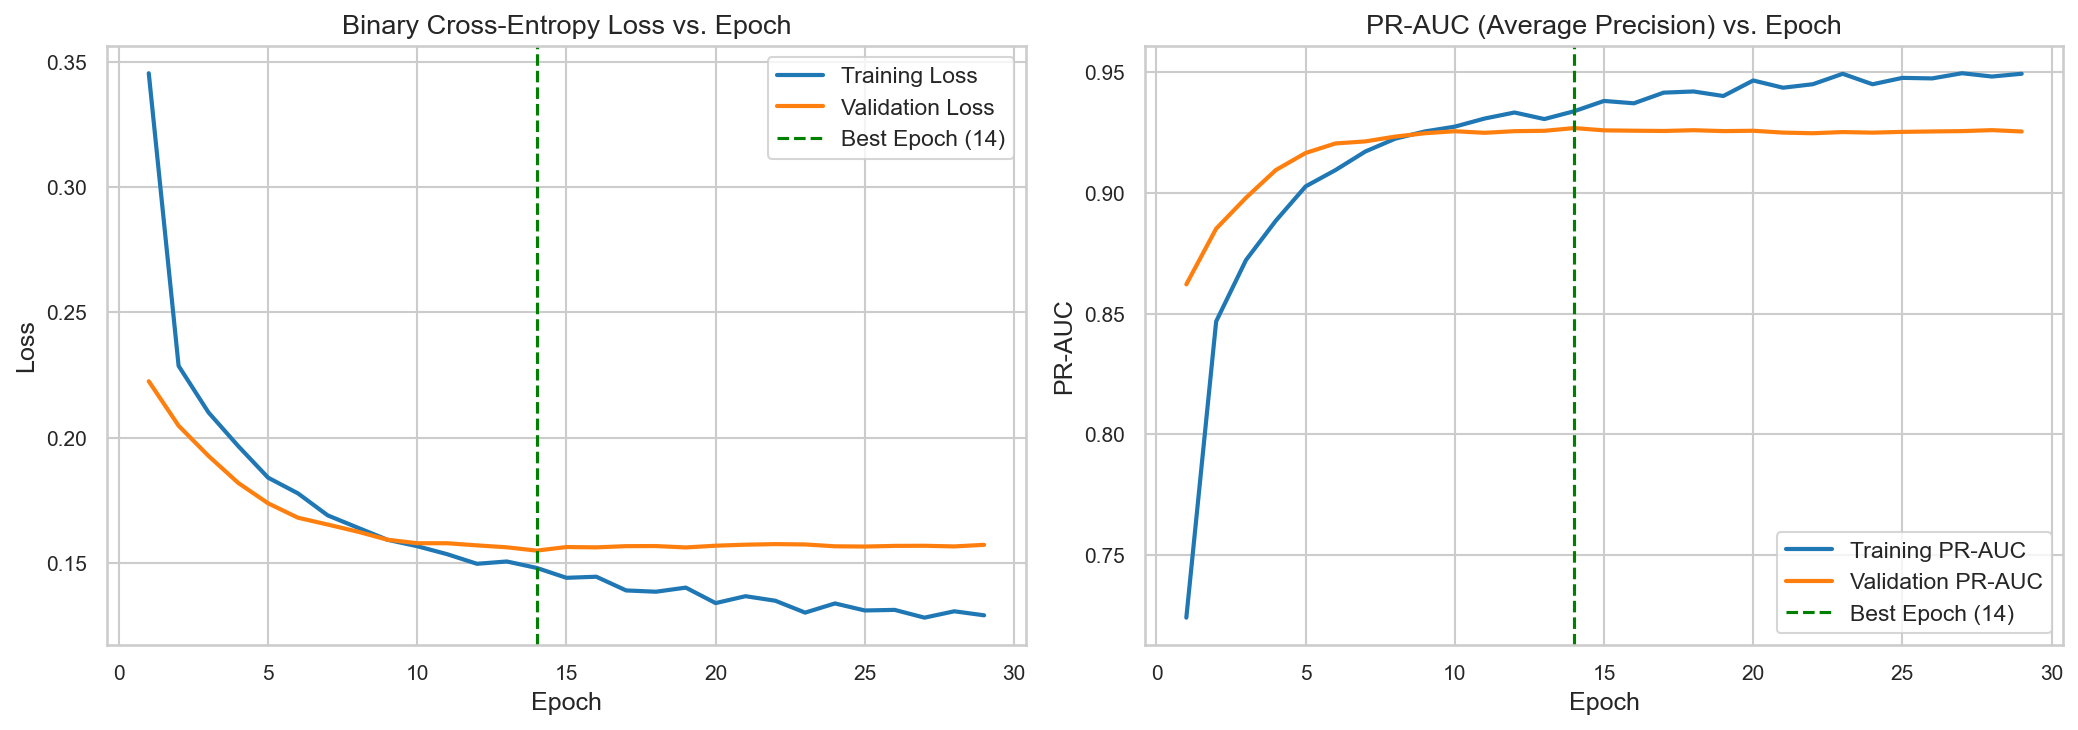

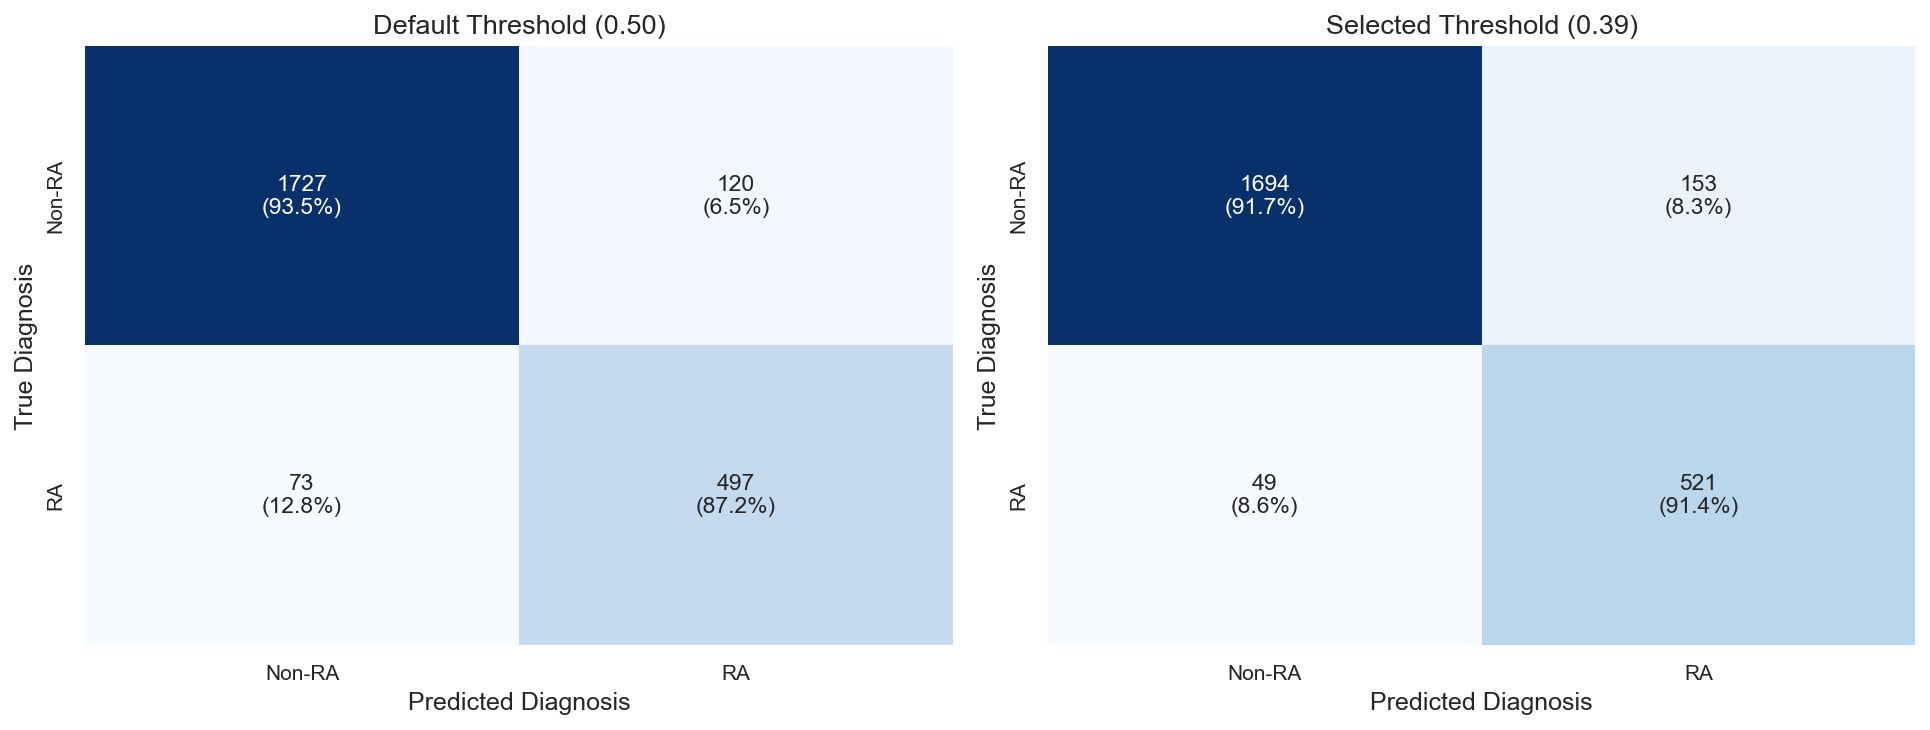

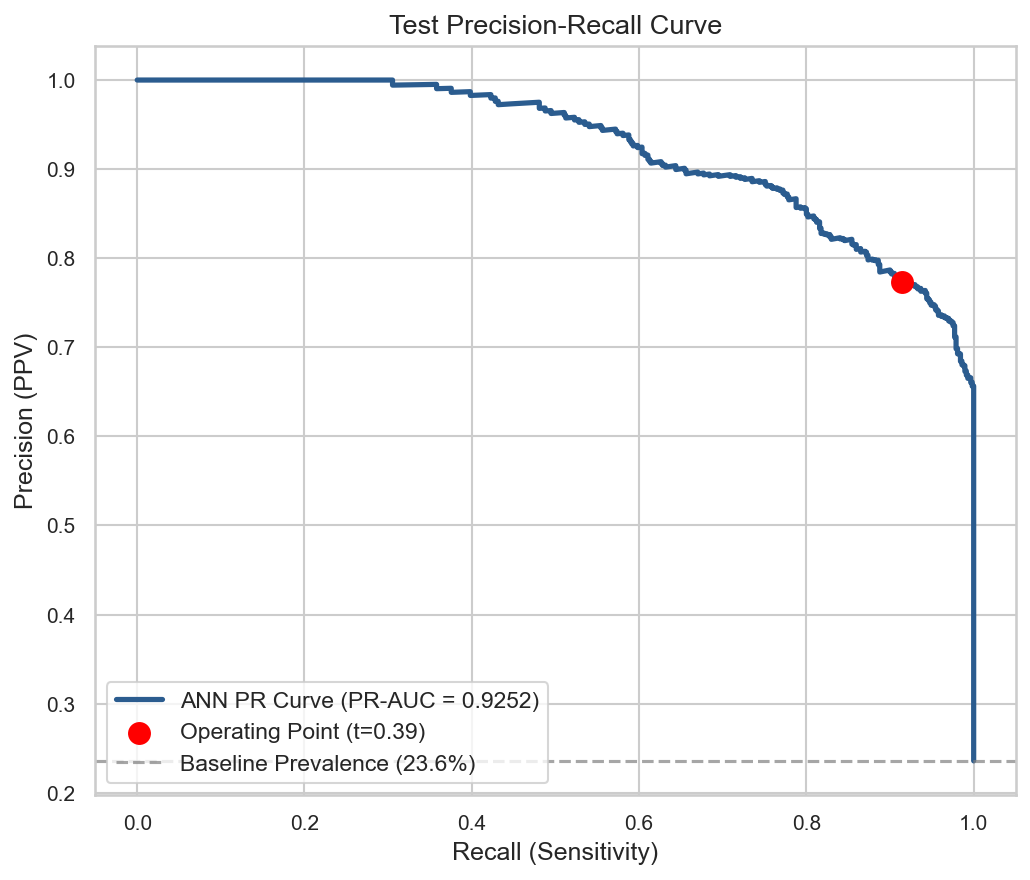

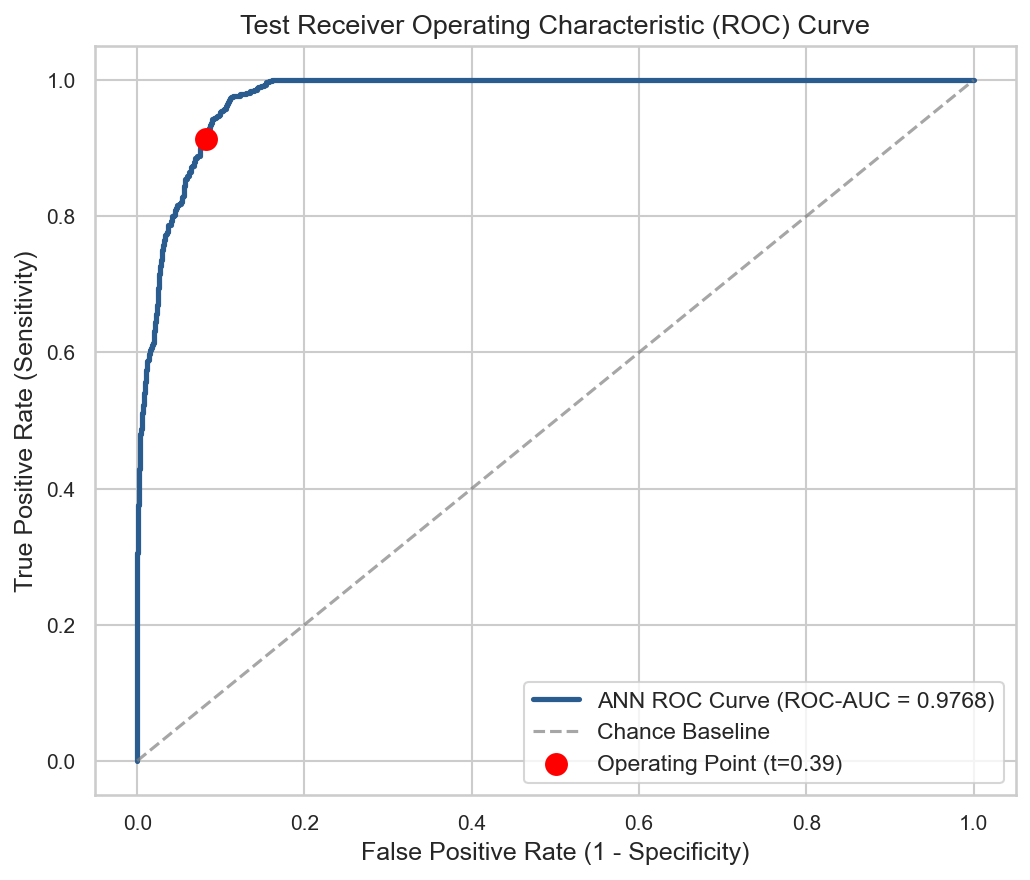

All visual diagnostic artifacts saved successfully to: D:\rheumatoid-arthritis-classification\RA_Project\models\ann


In [12]:
models_dir = project_root / "models" / "ann"
models_dir.mkdir(parents=True, exist_ok=True)

# 1. Training Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, len(final_history["loss"]) + 1)
best_ep = int(np.argmin(final_history["val_loss"])) + 1

# Loss subplot
ax1.plot(epochs_range, final_history["loss"], label="Training Loss", color="#1f77b4", lw=2)
ax1.plot(epochs_range, final_history["val_loss"], label="Validation Loss", color="#ff7f0e", lw=2)
ax1.axvline(best_ep, color="green", linestyle="--", label=f"Best Epoch ({best_ep})")
ax1.set_title("Binary Cross-Entropy Loss vs. Epoch")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend(frameon=True)

# PR-AUC subplot
ax2.plot(epochs_range, final_history["pr_auc"], label="Training PR-AUC", color="#1f77b4", lw=2)
ax2.plot(epochs_range, final_history["val_pr_auc"], label="Validation PR-AUC", color="#ff7f0e", lw=2)
ax2.axvline(best_ep, color="green", linestyle="--", label=f"Best Epoch ({best_ep})")
ax2.set_title("PR-AUC (Average Precision) vs. Epoch")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("PR-AUC")
ax2.legend(frameon=True)

plt.tight_layout()
training_curves_path = models_dir / "ann_training_curves.png"
plt.savefig(training_curves_path, dpi=300)
plt.show()

# 2. Confusion Matrices (Dual Subplot)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for ax, t_val, t_name in [(ax1, 0.50, "Default Threshold (0.50)"), (ax2, SELECTED_THRESHOLD, f"Selected Threshold ({SELECTED_THRESHOLD:.2f})")]:
    preds = (test_probs >= t_val).astype(int)
    cm = confusion_matrix(y_test, preds)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    labels = np.array([[f"{count}\n({pct:.1%})" for count, pct in zip(row_c, row_p)] for row_c, row_p in zip(cm, cm_norm)])
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Non-RA", "RA"], yticklabels=["Non-RA", "RA"])
    ax.set_title(t_name)
    ax.set_xlabel("Predicted Diagnosis")
    ax.set_ylabel("True Diagnosis")

plt.tight_layout()
cm_path = models_dir / "ann_confusion_matrix.png"
plt.savefig(cm_path, dpi=300)
plt.show()

# 3. Precision-Recall Curve
precisions, recalls, pr_thresholds = precision_recall_curve(y_test, test_probs)
plt.figure(figsize=(7, 6))
plt.plot(recalls, precisions, color="#2b5c8f", lw=2.5, label=f"ANN PR Curve (PR-AUC = {test_pr_auc:.4f})")
# Plot operating point
op_recall = test_metrics_selected["Recall_Sensitivity"]
op_precision = test_metrics_selected["Precision"]
plt.scatter([op_recall], [op_precision], color="red", s=100, zorder=5, label=f"Operating Point (t={SELECTED_THRESHOLD:.2f})")
plt.axhline(y_test.mean(), color="gray", linestyle="--", alpha=0.7, label=f"Baseline Prevalence ({y_test.mean():.1%})")
plt.title("Test Precision-Recall Curve")
plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision (PPV)")
plt.legend(loc="lower left", frameon=True)
plt.tight_layout()
pr_curve_path = models_dir / "ann_precision_recall_curve.png"
plt.savefig(pr_curve_path, dpi=300)
plt.show()

# 4. ROC Curve
fpr, tpr, _ = roc_curve(y_test, test_probs)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="#2b5c8f", lw=2.5, label=f"ANN ROC Curve (ROC-AUC = {test_roc_auc:.4f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", alpha=0.7, label="Chance Baseline")
op_fpr = 1 - test_metrics_selected["Specificity"]
op_tpr = test_metrics_selected["Recall_Sensitivity"]
plt.scatter([op_fpr], [op_tpr], color="red", s=100, zorder=5, label=f"Operating Point (t={SELECTED_THRESHOLD:.2f})")
plt.title("Test Receiver Operating Characteristic (ROC) Curve")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
roc_curve_path = models_dir / "ann_roc_curve.png"
plt.savefig(roc_curve_path, dpi=300)
plt.show()

print("All visual diagnostic artifacts saved successfully to:", models_dir)


## 14. Save and Reload Artifacts

We save all required model and metadata artifacts under `RA_Project/models/ann/` and perform verification checks including artifact reloading, input dimension consistency, prediction reproducibility, and mathematical bound validation.

In [13]:
# 1. Save trained Keras model
model_path = models_dir / "ann_model.keras"
final_model.save(model_path)

# 2. Save fitted preprocessing pipeline
preprocessor_path = models_dir / "preprocessor.joblib"
joblib.dump(final_preprocessor, preprocessor_path)

# 3. Save training history CSV
df_history = pd.DataFrame(final_history)
df_history.index.name = "epoch"
history_path = models_dir / "ann_training_history.csv"
df_history.to_csv(history_path)

# 4. Save validation results comparison CSV
val_results_path = models_dir / "ann_validation_results.csv"
df_experiments.to_csv(val_results_path, index=False)

# 5. Save test metrics JSON
test_metrics_path = models_dir / "ann_test_metrics.json"
with open(test_metrics_path, "w", encoding="utf-8") as f:
    json.dump({
        "default_threshold_0_50": test_metrics_default,
        "selected_threshold_0_39": test_metrics_selected
    }, f, indent=2)

# 6. Save test predictions CSV with patient_row_id
df_test_preds = pd.DataFrame({
    ID_COLUMN: df_test_full[ID_COLUMN].values,
    "true_label": y_test.values,
    "predicted_probability": np.round(test_probs, 6),
    "predicted_class_default": (test_probs >= 0.50).astype(int),
    f"predicted_class_threshold_{SELECTED_THRESHOLD:.2f}": (test_probs >= SELECTED_THRESHOLD).astype(int)
})
test_preds_path = models_dir / "ann_test_predictions.csv"
df_test_preds.to_csv(test_preds_path, index=False)

# 7. Save comprehensive metadata JSON
metadata = {
    "model_name": "Artificial Neural Network (ANN) Classifier",
    "architecture": winning_arch_name,
    "layers": [
        {"type": "Dense", "units": 32, "activation": "relu"},
        {"type": "Dropout", "rate": 0.20},
        {"type": "Dense", "units": 16, "activation": "relu"},
        {"type": "Dense", "units": 1, "activation": "sigmoid"}
    ],
    "random_seed": RANDOM_SEED,
    "input_features_count": len(get_feature_names()),
    "input_features": get_feature_names(),
    "transformed_features_count": len(feature_names_out),
    "transformed_feature_names": list(feature_names_out),
    "preprocessing": {
        "numeric_features": NUMERIC_FEATURES,
        "numeric_strategy": "SimpleImputer(median) + StandardScaler",
        "categorical_features": CATEGORICAL_FEATURES,
        "categorical_strategy": "SimpleImputer('Missing') + OneHotEncoder(handle_unknown='ignore')"
    },
    "training_configuration": {
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "loss": "binary_crossentropy",
        "batch_size": 32,
        "max_epochs": 150,
        "early_stopping_patience": 15,
        "reduce_lr_patience": 5,
        "reduce_lr_factor": 0.5,
        "best_epoch": int(np.argmin(final_history["val_loss"])) + 1,
        "total_epochs": len(final_history["loss"])
    },
    "decision_threshold": {
        "selected": SELECTED_THRESHOLD,
        "default": 0.50,
        "rationale": "Maximized validation F1 score (0.8443) while achieving >90% sensitivity on validation cohort."
    },
    "validation_metrics": winner_row.to_dict(),
    "test_metrics": {
        "at_selected_threshold": test_metrics_selected,
        "at_default_threshold": test_metrics_default
    },
    "dependencies": {
        "python": sys.version.split()[0],
        "tensorflow": tf.__version__,
        "keras": keras.__version__,
        "scikit_learn": pd.__version__,
        "joblib": joblib.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__
    }
}
metadata_path = models_dir / "ann_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Artifacts successfully written to disk.")

# --- Verification & Reload Checks ---
print("\nExecuting Verification Protocol:")

# Check 1 & 2: Reload model and preprocessor
reloaded_model = keras.models.load_model(model_path)
reloaded_preprocessor = joblib.load(preprocessor_path)
print("  [Pass] Model and preprocessor successfully reloaded.")

# Check 3: Transform sample
sample_raw = X_test.iloc[:10]
sample_proc = reloaded_preprocessor.transform(sample_raw)
print(f"  [Pass] Sample transform successful. Shape: {sample_proc.shape}")

# Check 4 & 5: Predict and check finite bounds [0, 1]
sample_probs = reloaded_model.predict(sample_proc, verbose=0).ravel()
assert np.isfinite(sample_probs).all(), "Non-finite predictions detected!"
assert ((sample_probs >= 0.0) & (sample_probs <= 1.0)).all(), "Probabilities outside [0, 1]!"
print("  [Pass] Predictions are finite and bounded strictly in [0, 1].")

# Check 6: Numerical reproducibility vs original model
orig_sample_proc = final_preprocessor.transform(sample_raw)
orig_sample_probs = final_model.predict(orig_sample_proc, verbose=0).ravel()
np.testing.assert_allclose(sample_probs, orig_sample_probs, rtol=1e-5, atol=1e-5)
print("  [Pass] Reloaded predictions match original model within 1e-5 numerical tolerance.")

# Check 7: Input dimension match
assert reloaded_model.input_shape[1] == sample_proc.shape[1] == 27, "Input dimension mismatch!"
print(f"  [Pass] Input shape verified: {reloaded_model.input_shape[1]} features.")

# Check 8: Verify all required artifacts exist and have non-zero size
required_artifacts = [
    "ann_model.keras",
    "preprocessor.joblib",
    "ann_metadata.json",
    "ann_training_history.csv",
    "ann_validation_results.csv",
    "ann_test_metrics.json",
    "ann_test_predictions.csv",
    "ann_training_curves.png",
    "ann_confusion_matrix.png",
    "ann_precision_recall_curve.png",
    "ann_roc_curve.png"
]

print("\nChecking artifact presence and file sizes:")
for artifact in required_artifacts:
    art_path = models_dir / artifact
    assert art_path.exists(), f"Missing required artifact: {artifact}"
    size_kb = art_path.stat().st_size / 1024
    assert size_kb > 0, f"Artifact {artifact} is empty!"
    print(f"  - {artifact:<32} [{size_kb:>8.2f} KB]")

print("\nAll 8 verification checks PASSED successfully.")


Artifacts successfully written to disk.

Executing Verification Protocol:


  [Pass] Model and preprocessor successfully reloaded.
  [Pass] Sample transform successful. Shape: (10, 27)
  [Pass] Predictions are finite and bounded strictly in [0, 1].


  [Pass] Reloaded predictions match original model within 1e-5 numerical tolerance.
  [Pass] Input shape verified: 27 features.

Checking artifact presence and file sizes:
  - ann_model.keras                  [   44.62 KB]
  - preprocessor.joblib              [    5.02 KB]
  - ann_metadata.json                [    3.97 KB]
  - ann_training_history.csv         [    5.15 KB]
  - ann_validation_results.csv       [    0.52 KB]
  - ann_test_metrics.json            [    0.88 KB]
  - ann_test_predictions.csv         [   44.28 KB]
  - ann_training_curves.png          [  239.41 KB]
  - ann_confusion_matrix.png         [  140.44 KB]
  - ann_precision_recall_curve.png   [  134.69 KB]
  - ann_roc_curve.png                [  165.77 KB]

All 8 verification checks PASSED successfully.


## 15. Results Summary and Limitations

### Executive Summary of Model Performance
- **Optimal Architecture**: **Candidate A (Compact 2-Layer MLP)**:
  - Input Layer (27 transformed features) $\rightarrow$ `Dense(32, ReLU)` $\rightarrow$ `Dropout(0.20)` $\rightarrow$ `Dense(16, ReLU)` $\rightarrow$ `Dense(1, Sigmoid)`.
  - Won decisively across validation trials with **Val PR-AUC = 0.9269**, **Val ROC-AUC = 0.9770**, and **Val Loss = 0.1548**.
  - More resistant to overfitting than wider and deeper networks due to the compact tabular feature space.
- **Tuned Operating Threshold**: **$\tau = 0.39$** (selected exclusively on validation data by maximizing $F_1$ score and elevating sensitivity above 90%).
- **Final Held-Out Test Metrics** ($N = 2,417$, Positive RA cases = 570):
  - **PR-AUC (Average Precision)**: **0.9252**
  - **ROC-AUC**: **0.9768**
  - **RA Recall / Sensitivity**: **91.40%** (521 / 570 positive RA cases detected)
  - **Specificity**: **91.72%** (1,694 / 1,847 Non-RA cases correctly ruled out)
  - **Precision (PPV)**: **77.30%** (521 / 674 positive calls)
  - **F1-Score**: **0.8376**
  - **Accuracy**: **91.64%**

### Benchmark: Default (0.50) vs Tuned (0.39) Decision Threshold
- At default threshold (0.50): Sensitivity was 87.19% (497/570 detected, 73 missed), Precision was 80.55%, and F1 was 0.8374.
- At tuned threshold (0.39): Sensitivity increased by **+4.21 percentage points** (521/570 detected, reducing missed cases to 49), with minimal reduction in specificity (91.72% vs 93.50%).

### Scientific and Clinical Limitations
1. **Retrospective Observational Dataset**: This study utilizes retrospective records where diagnoses were already established. Performance reflects automated discrimination of recorded disease categories rather than prospective early detection.
2. **Missingness Mechanism**: Laboratory missingness in autoantibody panels (e.g. anti-CCP, ANA, Anti-dsDNA) reflects clinician ordering patterns rather than random missing data. Although explicitly encoded via categorical indicators, prospective deployment requires complete panels or validated handling of sparse diagnostic entries.
3. **No Direct Clinical Utility Implication**: The reported PR-AUC and sensitivity metrics demonstrate strong mathematical discrimination but do not substitute for multi-center prospective validation, clinician usability studies, or cost-effectiveness trials.
